<a href="https://colab.research.google.com/github/samarg4617-creator/imageprocess/blob/main/assingment6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter odd filter size: 2
Padding: 1.Zero  2.Replication: 1
Enter Gaussian sigma: 2


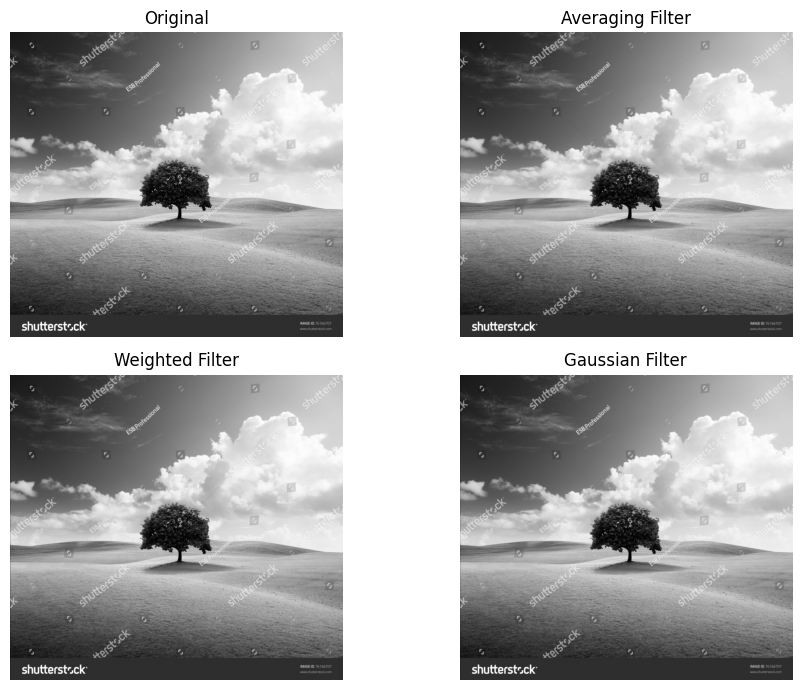

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("sampleimage.jpg", 0)

if img is None:
    print("Image not found")
    exit()

img = img.astype(float)

n = int(input("Enter odd filter size: "))
p = int(input("Padding: 1.Zero  2.Replication: "))
sigma = float(input("Enter Gaussian sigma: "))

pad = n // 2

if p == 1:
    a = np.pad(img, pad, mode='constant')
else:
    a = np.pad(img, pad, mode='edge')

h, w = img.shape

avg = np.ones((n, n)) / (n * n)
weight = np.zeros((n, n))
gauss = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        x = i - pad
        y = j - pad

        # Given weighted filter
        weight[i, j] = max(abs(x), abs(y))

        # Gaussian filter
        gauss[i, j] = np.exp(-(x*x + y*y) / (2*sigma*sigma))

if weight.sum() == 0:
    weight[pad, pad] = 1

weight = weight / weight.sum()
gauss = gauss / gauss.sum()

def filtering(kernel):
    out = np.zeros((h, w))

    for i in range(h):
        for j in range(w):
            region = a[i:i+n, j:j+n]
            out[i, j] = np.sum(region * kernel)

    return np.clip(out, 0, 255).astype(np.uint8)


r1 = filtering(avg)
r2 = filtering(weight)
r3 = filtering(gauss)

plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(r1, cmap='gray')
plt.title("Averaging Filter")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(r2, cmap='gray')
plt.title("Weighted Filter")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(r3, cmap='gray')
plt.title("Gaussian Filter")
plt.axis('off')

plt.tight_layout()
plt.show()